# Import Library

In [1]:
#202431098_Naura Putri
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report,
                             mean_squared_error, mean_absolute_error, r2_score)
RANDOM_STATE = 42

# Memuat Dataset

In [2]:
#202431098_Naura Putri
df = pd.read_csv("02_diabetes.csv")
print("Ukuran dataset (baris, kolom):", df.shape)
print(df.head(10).to_string())

Ukuran dataset (baris, kolom): (100000, 9)
   gender   age  hypertension  heart_disease smoking_history    bmi  HbA1c_level  blood_glucose_level  diabetes
0  Female  80.0             0              1           never  25.19          6.6                  140         0
1  Female  54.0             0              0         No Info  27.32          6.6                   80         0
2    Male  28.0             0              0           never  27.32          5.7                  158         0
3  Female  36.0             0              0         current  23.45          5.0                  155         0
4    Male  76.0             1              1         current  20.14          4.8                  155         0
5  Female  20.0             0              0           never  27.32          6.6                   85         0
6  Female  44.0             0              0           never  19.31          6.5                  200         1
7  Female  79.0             0              0         No Info 

# Exploratory Data Analysis (EDA)
### 3.1 Informasi Umum Dataset

In [3]:
#202431098_Naura Putri
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 6.9 MB


In [4]:
#202431098_Naura Putri
print("Jumlah nilai kosong per kolom:")
print(df.isna().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())

Jumlah nilai kosong per kolom:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

Jumlah baris duplikat: 3854


In [5]:
#202431098_Naura Putri
print(df.describe().T.round(3).to_string())

                        count     mean     std    min     25%     50%     75%     max
age                  100000.0   41.886  22.517   0.08   24.00   43.00   60.00   80.00
hypertension         100000.0    0.075   0.263   0.00    0.00    0.00    0.00    1.00
heart_disease        100000.0    0.039   0.195   0.00    0.00    0.00    0.00    1.00
bmi                  100000.0   27.321   6.637  10.01   23.63   27.32   29.58   95.69
HbA1c_level          100000.0    5.528   1.071   3.50    4.80    5.80    6.20    9.00
blood_glucose_level  100000.0  138.058  40.708  80.00  100.00  140.00  159.00  300.00
diabetes             100000.0    0.085   0.279   0.00    0.00    0.00    0.00    1.00


### 3.2 Distribusi Target (`diabetes`)

diabetes
0    91500
1     8500
Name: count, dtype: int64
diabetes
0    91.5 %
1     8.5 %
Name: count, dtype: str


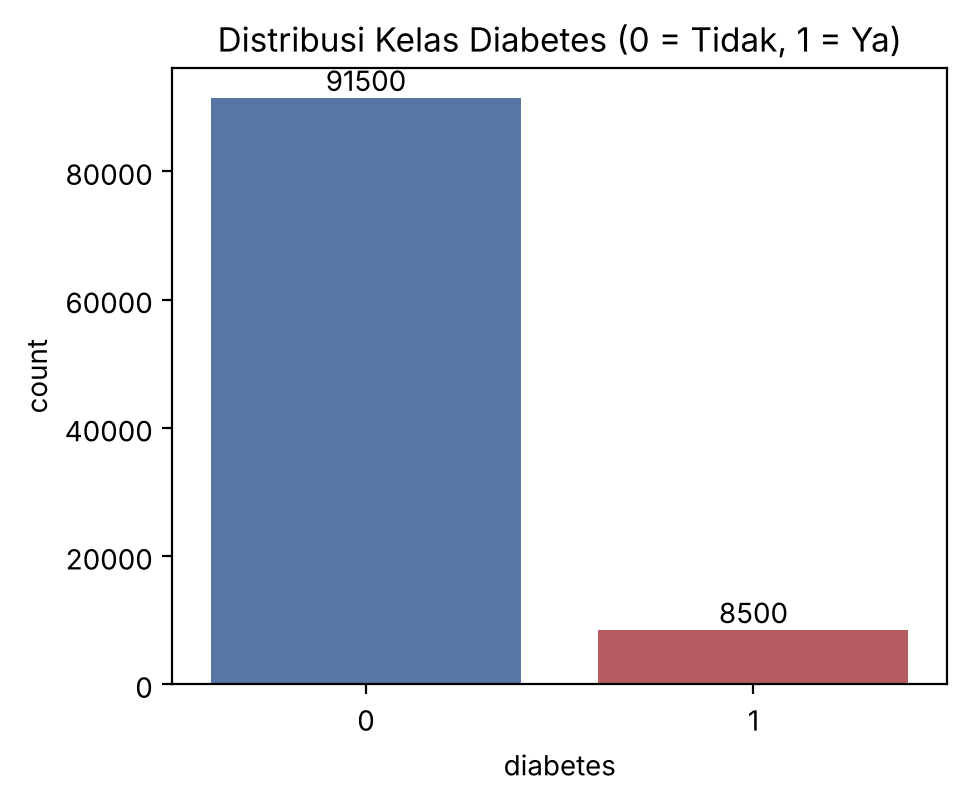

In [6]:
#202431098_Naura Putri
counts = df["diabetes"].value_counts()
print(counts)
print((counts / len(df) * 100).round(2).astype(str) + " %")

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x="diabetes", data=df, ax=ax, palette=["#4C72B0", "#C44E52"])
ax.set_title("Distribusi Kelas Diabetes (0 = Tidak, 1 = Ya)")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")

### 3.3 Fitur Kategorikal

Persentase penderita diabetes per kategori (%):
gender
Female    7.62
Male      9.75
Other     0.00
Name: diabetes, dtype: float64
smoking_history
No Info         4.06
current        10.21
ever           11.79
former         17.00
never           9.53
not current    10.70
Name: diabetes, dtype: float64


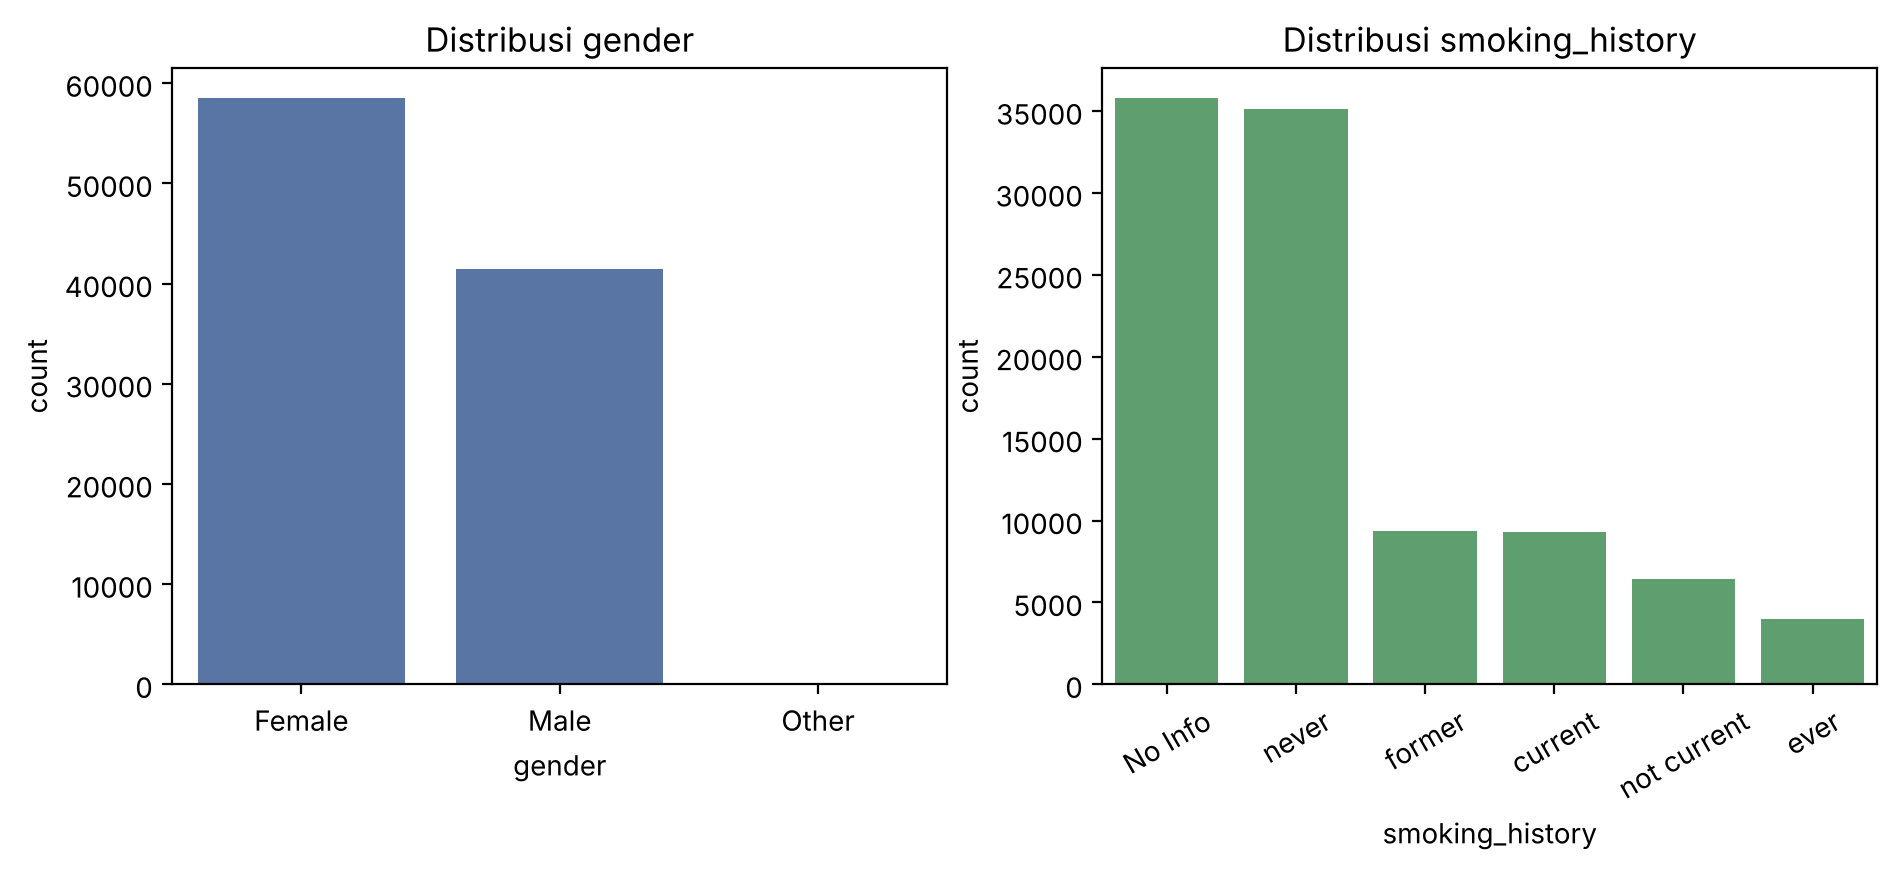

In [7]:
#202431098_Naura Putri
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="gender", data=df, ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribusi gender")
sns.countplot(x="smoking_history", data=df, ax=axes[1], color="#55A868",
              order=df["smoking_history"].value_counts().index)
axes[1].set_title("Distribusi smoking_history")
axes[1].tick_params(axis="x", rotation=30)

print("Persentase penderita diabetes per kategori (%):")
print((df.groupby("gender")["diabetes"].mean() * 100).round(2))
print((df.groupby("smoking_history")["diabetes"].mean() * 100).round(2))

### 3.4 Fitur Numerik

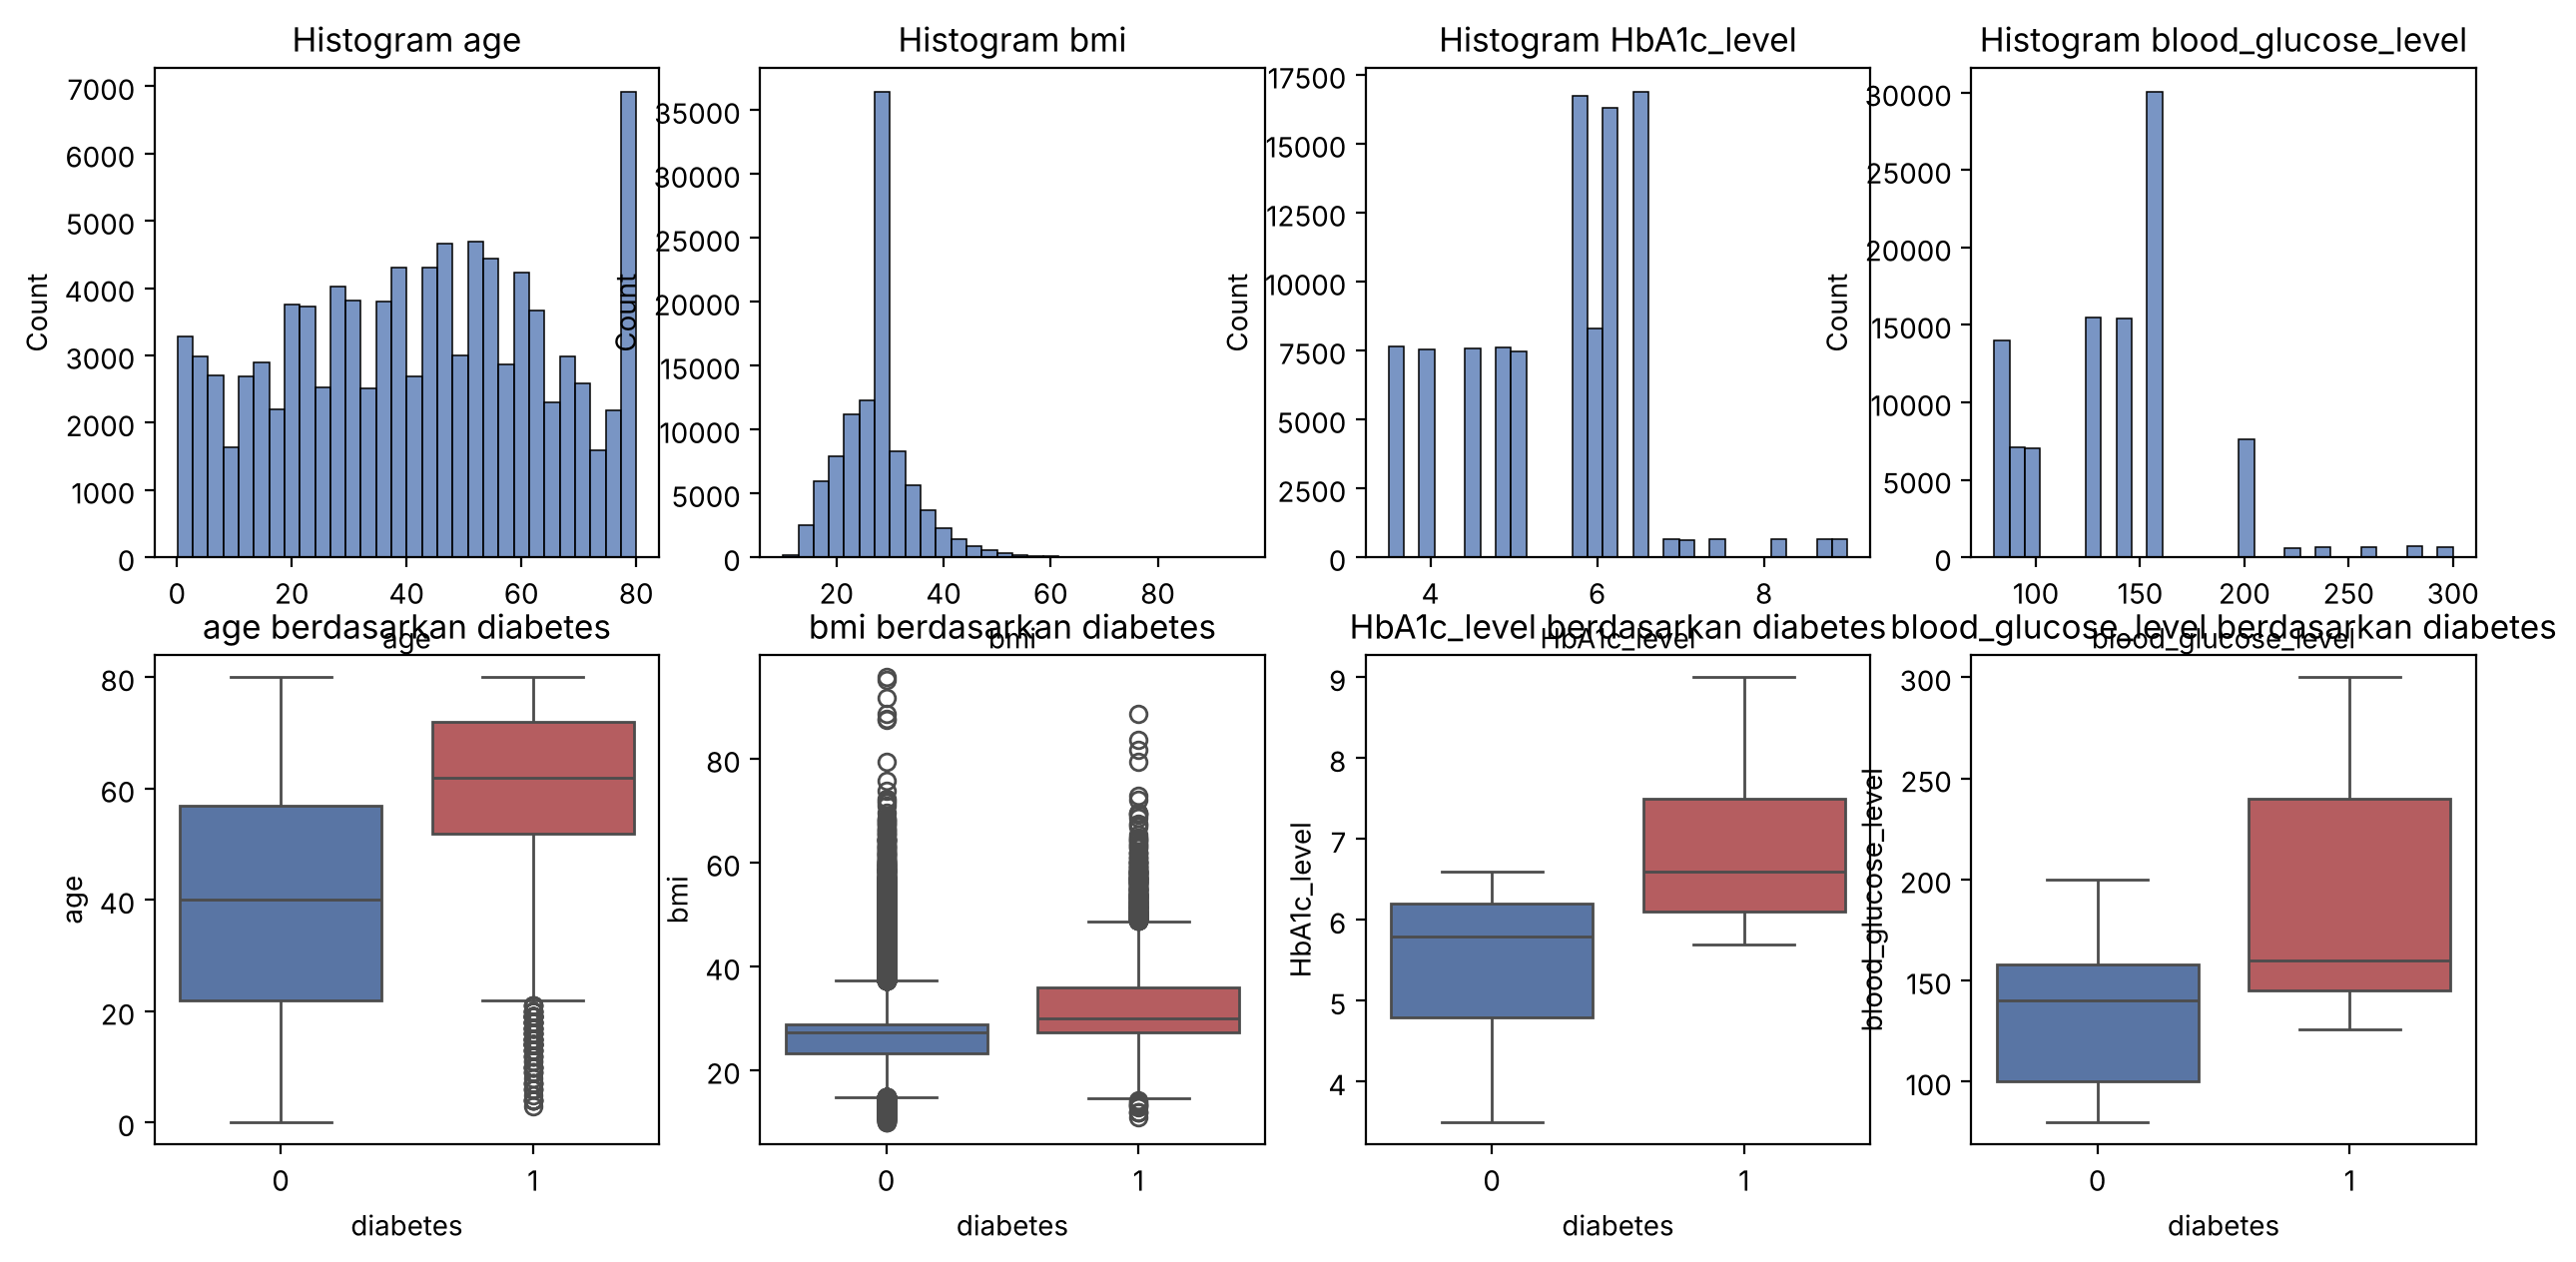

In [8]:
#202431098_Naura Putri
num_cols = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for i, c in enumerate(num_cols):
    sns.histplot(df[c], bins=30, kde=False, ax=axes[0, i], color="#4C72B0")
    axes[0, i].set_title(f"Histogram {c}")
    sns.boxplot(x="diabetes", y=c, data=df, ax=axes[1, i], palette=["#4C72B0", "#C44E52"])
    axes[1, i].set_title(f"{c} berdasarkan diabetes")

### 3.5 Korelasi Antar Fitur Numerik

blood_glucose_level    0.420
HbA1c_level            0.401
age                    0.258
bmi                    0.214
hypertension           0.198
heart_disease          0.172
Name: diabetes, dtype: float64


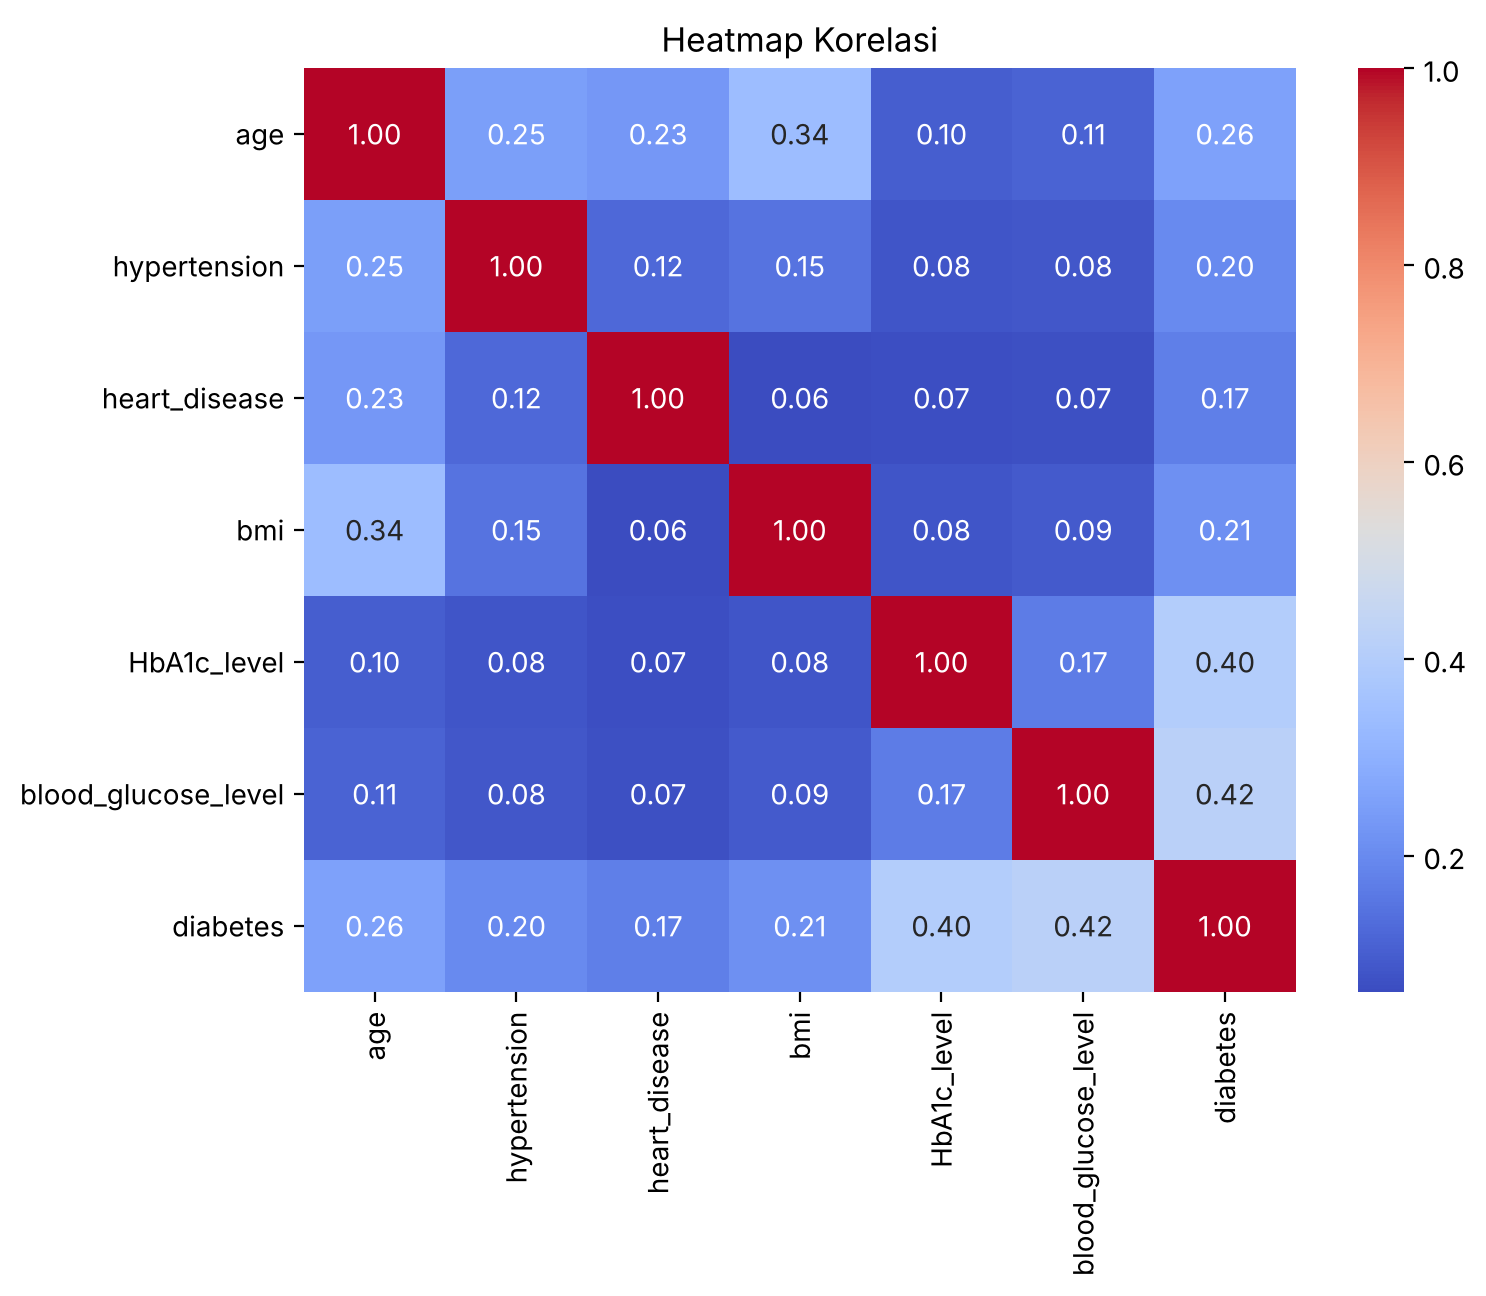

In [9]:
#202431098_Naura Putri
num_all = ["age", "hypertension", "heart_disease", "bmi", "HbA1c_level",
           "blood_glucose_level", "diabetes"]
corr = df[num_all].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
ax.set_title("Heatmap Korelasi")
print(corr["diabetes"].drop("diabetes").sort_values(ascending=False).round(3))

## 4. Preprocessing Data


In [10]:
#202431098_Naura Putri
print("Sebelum hapus duplikat:", df.shape)
df_clean = df.drop_duplicates().reset_index(drop=True)
print("Sesudah hapus duplikat:", df_clean.shape)
print("Nilai kosong:", int(df_clean.isna().sum().sum()))

Sebelum hapus duplikat: (100000, 9)
Sesudah hapus duplikat: (96146, 9)
Nilai kosong: 0


In [11]:
#202431098_Naura Putri
df_enc = pd.get_dummies(df_clean, columns=["gender", "smoking_history"], drop_first=True, dtype=int)
print("Kolom setelah encoding:", list(df_enc.columns))

X = df_enc.drop(columns="diabetes")
y = df_enc["diabetes"]
print("Bentuk X:", X.shape, "| Bentuk y:", y.shape)

Kolom setelah encoding: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes', 'gender_Male', 'gender_Other', 'smoking_history_current', 'smoking_history_ever', 'smoking_history_former', 'smoking_history_never', 'smoking_history_not current']
Bentuk X: (96146, 13) | Bentuk y: (96146,)


In [12]:
#202431098_Naura Putri
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Proporsi diabetes (train):", round(y_train.mean(), 4), "| (test):", round(y_test.mean(), 4))

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit hanya di data latih
X_test_s = scaler.transform(X_test)
print("Rata-rata fitur train setelah scaling (≈0):", X_train_s.mean(axis=0).round(3)[:5], "...")

X_train: (76916, 13) | X_test: (19230, 13)
Proporsi diabetes (train): 0.0882 | (test): 0.0882
Rata-rata fitur train setelah scaling (≈0): [-0.  0.  0. -0. -0.] ...


## 5. Algoritma 1: K-Nearest Neighbors (KNN)
### 5.1 Baseline: dengan vs tanpa scaling (K = 5)

In [13]:
#202431098_Naura Putri
knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
knn_scl = KNeighborsClassifier(n_neighbors=5).fit(X_train_s, y_train)
acc_raw = accuracy_score(y_test, knn_raw.predict(X_test))
acc_scl = accuracy_score(y_test, knn_scl.predict(X_test_s))
print(f"Akurasi KNN (K=5) tanpa scaling : {acc_raw:.4f}")
print(f"Akurasi KNN (K=5) dengan scaling: {acc_scl:.4f}")

Akurasi KNN (K=5) tanpa scaling : 0.9541
Akurasi KNN (K=5) dengan scaling: 0.9591


### 5.2 Pemilihan Nilai K (5-fold Cross Validation pada data latih)

Akurasi CV per K:
  K= 1  ->  0.9451
  K= 3  ->  0.9553
  K= 5  ->  0.9581
  K= 7  ->  0.9588
  K= 9  ->  0.9587
  K=11  ->  0.9587
  K=13  ->  0.9588
  K=15  ->  0.9587
  K=17  ->  0.9584
  K=19  ->  0.9581
  K=21  ->  0.9576
  K=23  ->  0.9572
  K=25  ->  0.9571
  K=27  ->  0.9569
  K=29  ->  0.9565
  K=31  ->  0.9562

K terbaik = 13 (akurasi CV = 0.9588)


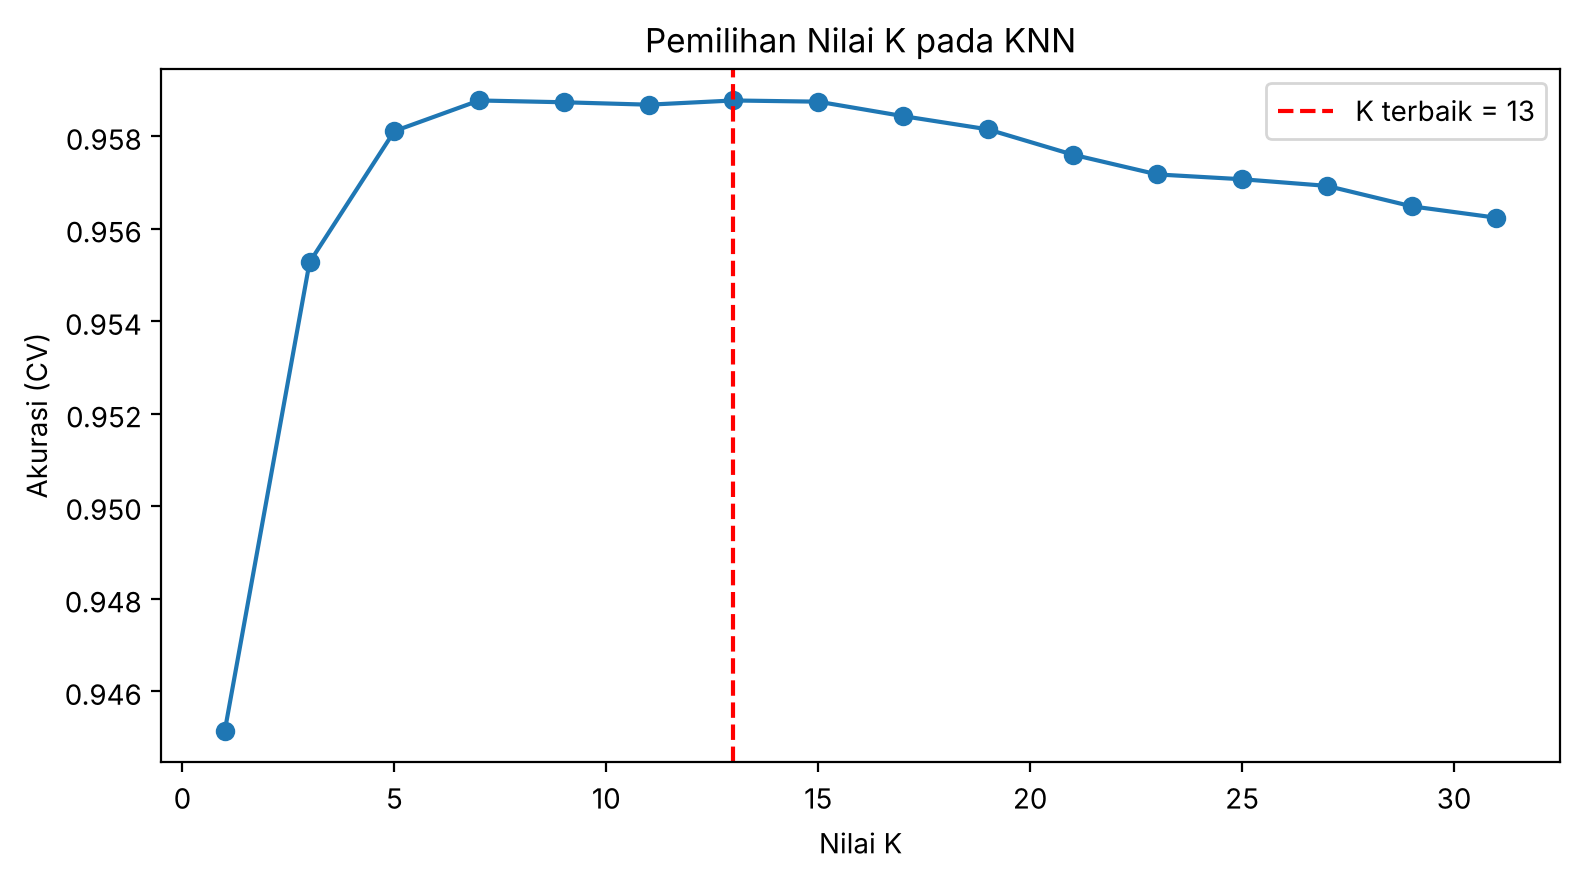

In [14]:
#202431098_Naura Putri
k_values = list(range(1, 32, 2))
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = []
for k in k_values:
    s = cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train_s, y_train,
                        cv=skf, scoring="accuracy", n_jobs=-1)
    cv_scores.append(s.mean())

best_k = k_values[int(np.argmax(cv_scores))]
print("Akurasi CV per K:")
for k, s in zip(k_values, cv_scores):
    print(f"  K={k:2d}  ->  {s:.4f}")
print(f"\nK terbaik = {best_k} (akurasi CV = {max(cv_scores):.4f})")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(k_values, cv_scores, marker="o")
ax.axvline(best_k, color="red", linestyle="--", label=f"K terbaik = {best_k}")
ax.set_xlabel("Nilai K"); ax.set_ylabel("Akurasi (CV)")
ax.set_title("Pemilihan Nilai K pada KNN"); ax.legend()
plt.tight_layout(); plt.show()

### 5.3 Evaluasi Model KNN Final pada Data Uji

K = 13
Akurasi  : 0.9608
Presisi  : 0.9546
Recall   : 0.5831
F1-score : 0.7240

                precision    recall  f1-score   support

Tidak Diabetes     0.9611    0.9973    0.9789     17534
      Diabetes     0.9546    0.5831    0.7240      1696

      accuracy                         0.9608     19230
     macro avg     0.9579    0.7902    0.8515     19230
  weighted avg     0.9606    0.9608    0.9564     19230



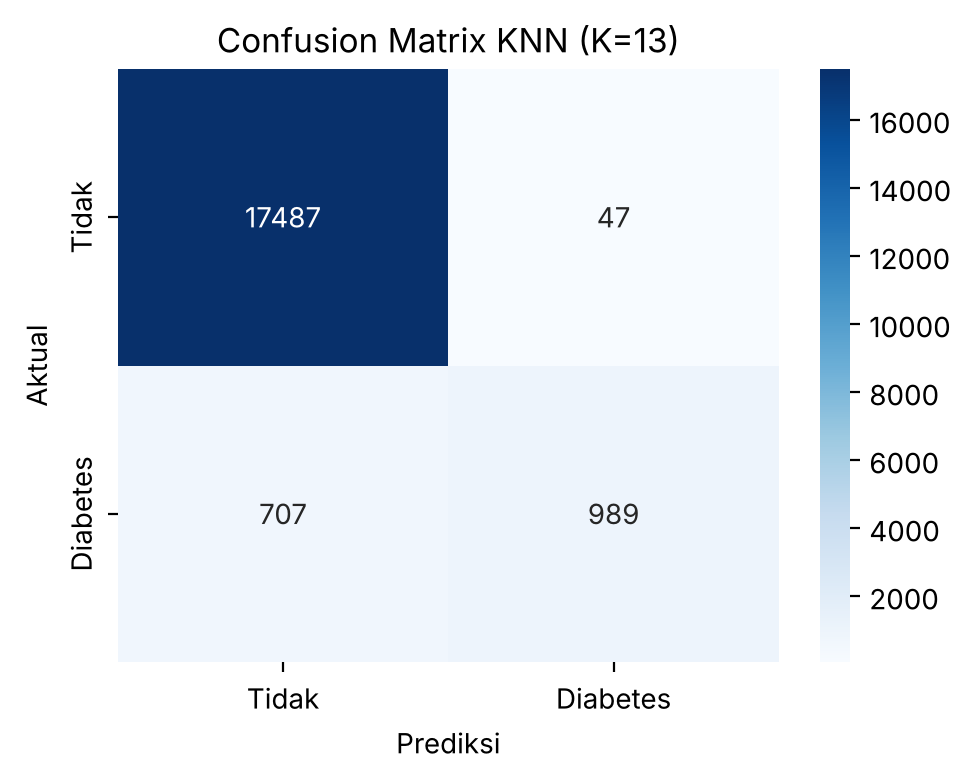

In [15]:
#202431098_Naura Putri
knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_s, y_train)
y_pred_knn = knn.predict(X_test_s)

acc_knn = accuracy_score(y_test, y_pred_knn)
pre_knn = precision_score(y_test, y_pred_knn)
rec_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)
print(f"K = {best_k}")
print(f"Akurasi  : {acc_knn:.4f}")
print(f"Presisi  : {pre_knn:.4f}")
print(f"Recall   : {rec_knn:.4f}")
print(f"F1-score : {f1_knn:.4f}\n")
print(classification_report(y_test, y_pred_knn, target_names=["Tidak Diabetes", "Diabetes"], digits=4))

cm = confusion_matrix(y_test, y_pred_knn)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=["Tidak", "Diabetes"], yticklabels=["Tidak", "Diabetes"])
ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual"); ax.set_title(f"Confusion Matrix KNN (K={best_k})")
plt.tight_layout(); plt.show()

## 6. Algoritma 2: Regresi Linear


In [16]:
#202431098_Naura Putri
lr = LinearRegression().fit(X_train_s, y_train)
score_test = lr.predict(X_test_s)

print("Intercept:", round(lr.intercept_, 4))
coef = pd.Series(lr.coef_, index=X.columns).sort_values(ascending=False)
print("\nKoefisien (fitur ter-standarisasi):")
print(coef.round(4))

print("\n--- Metrik regresi pada data uji ---")
print(f"MAE : {mean_absolute_error(y_test, score_test):.4f}")
print(f"MSE : {mean_squared_error(y_test, score_test):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, score_test)):.4f}")
print(f"R²  : {r2_score(y_test, score_test):.4f}")

Intercept: 0.0882

Koefisien (fitur ter-standarisasi):
blood_glucose_level            0.0944
HbA1c_level                    0.0891
age                            0.0323
bmi                            0.0268
hypertension                   0.0252
heart_disease                  0.0230
gender_Male                    0.0076
smoking_history_former         0.0065
smoking_history_never          0.0038
smoking_history_not current    0.0025
smoking_history_current        0.0013
smoking_history_ever           0.0011
gender_Other                  -0.0005
dtype: float64

--- Metrik regresi pada data uji ---
MAE : 0.1573
MSE : 0.0519
RMSE: 0.2279
R²  : 0.3542


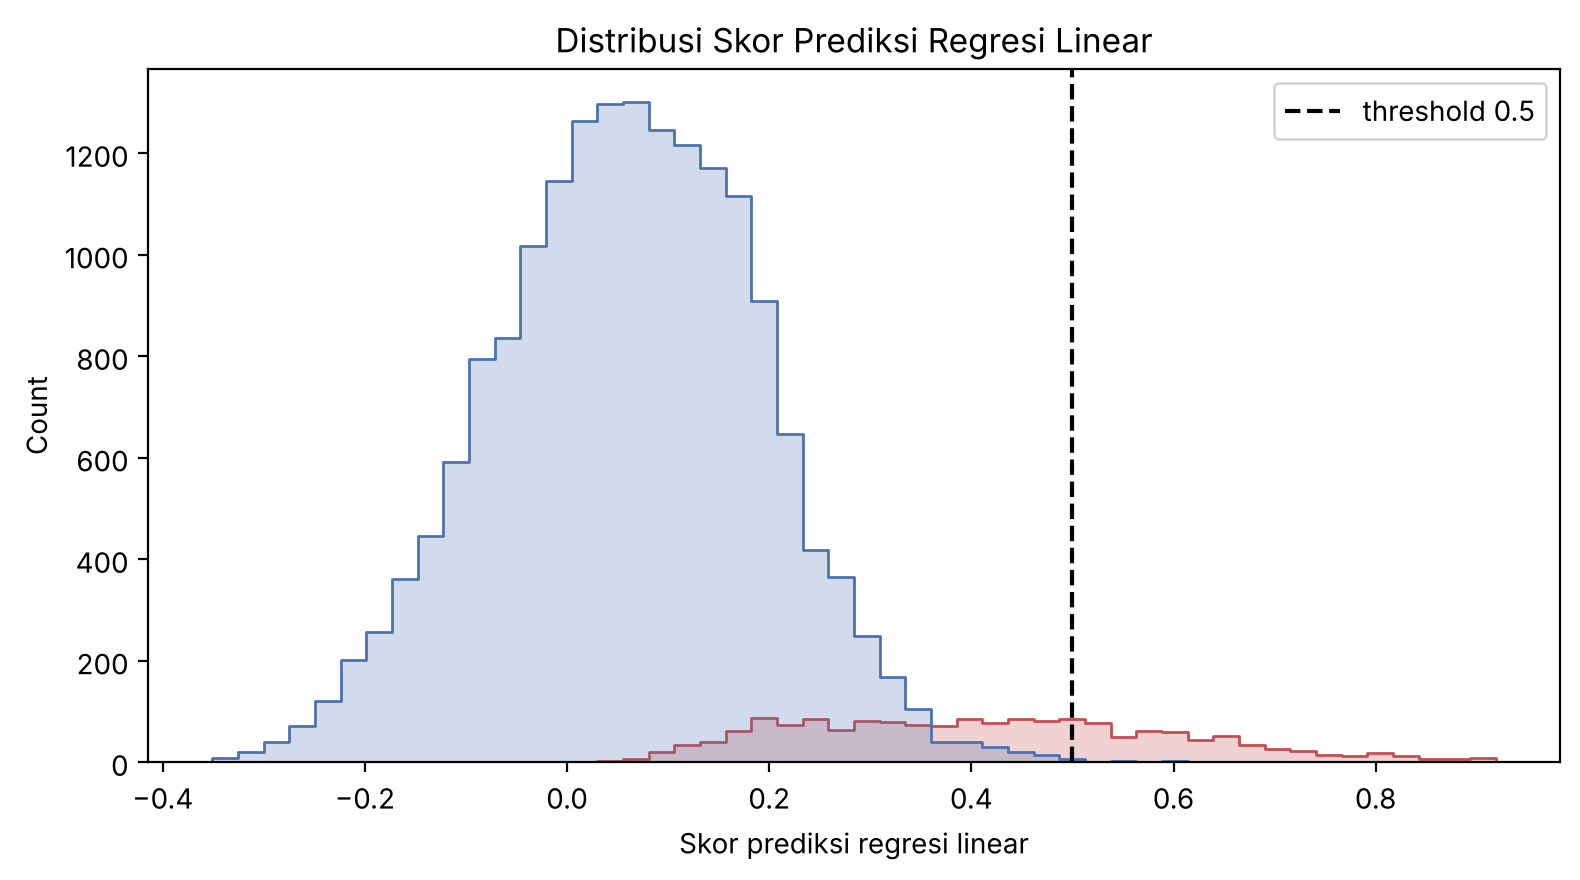

In [17]:
#202431098_Naura Putri
# Visualisasi skor prediksi regresi linear per kelas aktual
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(x=score_test, hue=y_test.values, bins=50, ax=ax, palette=["#4C72B0", "#C44E52"], element="step")
ax.axvline(0.5, color="black", linestyle="--", label="threshold 0.5")
ax.set_xlabel("Skor prediksi regresi linear"); ax.set_title("Distribusi Skor Prediksi Regresi Linear")
ax.legend()
plt.tight_layout(); plt.show()

### 6.1 Klasifikasi dengan Threshold

Threshold terbaik (maks F1 pada data latih) = 0.33

      Skenario  Akurasi  Presisi  Recall     F1
 Threshold 0.5   0.9396   0.9837  0.3208 0.4838
Threshold 0.33   0.9529   0.7902  0.6350 0.7042

Classification report (threshold 0.5):
                precision    recall  f1-score   support

Tidak Diabetes     0.9383    0.9995    0.9679     17534
      Diabetes     0.9837    0.3208    0.4838      1696

      accuracy                         0.9396     19230
     macro avg     0.9610    0.6601    0.7259     19230
  weighted avg     0.9423    0.9396    0.9252     19230



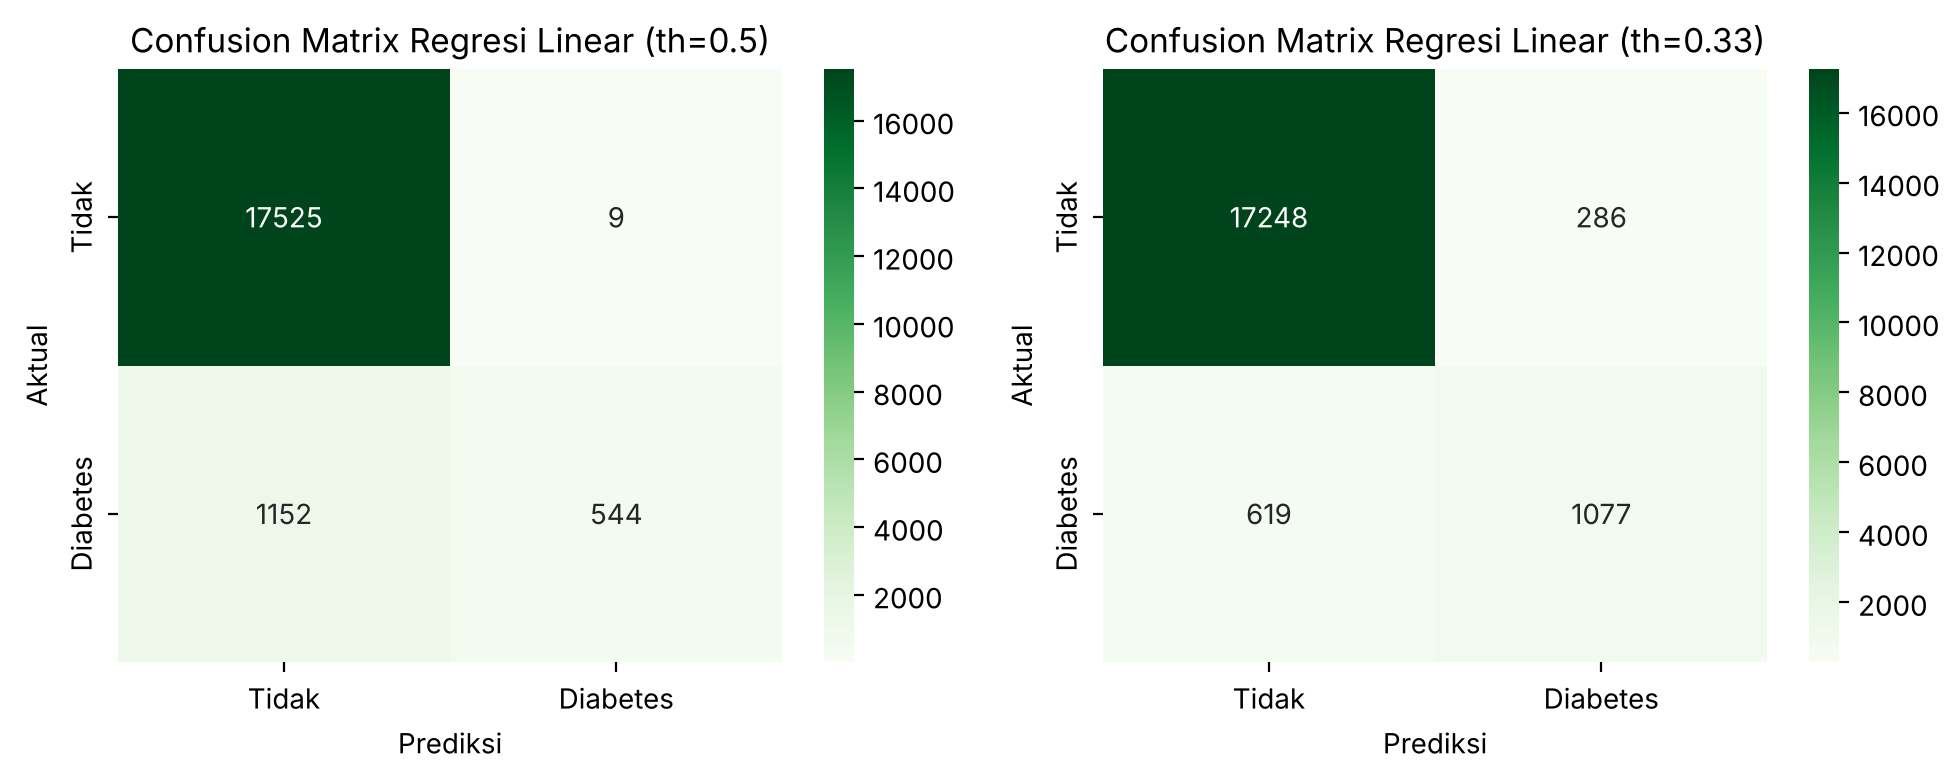

In [18]:
#202431098_Naura Putri
# (a) threshold standar 0.5
pred_05 = (score_test >= 0.5).astype(int)

# (b) threshold terbaik dari data latih (maksimum F1)
score_train = lr.predict(X_train_s)
ths = np.arange(0.05, 0.60, 0.01)
f1s = [f1_score(y_train, (score_train >= t).astype(int)) for t in ths]
best_th = float(ths[int(np.argmax(f1s))])
pred_best = (score_test >= best_th).astype(int)
print(f"Threshold terbaik (maks F1 pada data latih) = {best_th:.2f}\n")

rows = []
for name, p in [("Threshold 0.5", pred_05), (f"Threshold {best_th:.2f}", pred_best)]:
    rows.append([name, accuracy_score(y_test, p), precision_score(y_test, p, zero_division=0),
                 recall_score(y_test, p), f1_score(y_test, p)])
res_lr = pd.DataFrame(rows, columns=["Skenario", "Akurasi", "Presisi", "Recall", "F1"]).round(4)
print(res_lr.to_string(index=False))

acc_lr, pre_lr, rec_lr, f1_lr = rows[0][1:]          # threshold standar 0.5 sebagai hasil utama
print("\nClassification report (threshold 0.5):")
print(classification_report(y_test, pred_05, target_names=["Tidak Diabetes", "Diabetes"], digits=4, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, p, t in zip(axes, [pred_05, pred_best], ["0.5", f"{best_th:.2f}"]):
    sns.heatmap(confusion_matrix(y_test, p), annot=True, fmt="d", cmap="Greens", ax=ax,
                xticklabels=["Tidak", "Diabetes"], yticklabels=["Tidak", "Diabetes"])
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual"); ax.set_title(f"Confusion Matrix Regresi Linear (th={t})")
plt.tight_layout(); plt.show()

## 7. Perbandingan Model

                   Model  Akurasi  Presisi  Recall     F1
              KNN (K=13)   0.9608   0.9546  0.5831 0.7240
 Regresi Linear (th=0.5)   0.9396   0.9837  0.3208 0.4838
Regresi Linear (th=0.33)   0.9529   0.7902  0.6350 0.7042

Baseline (selalu menebak 'Tidak Diabetes'): 0.9118


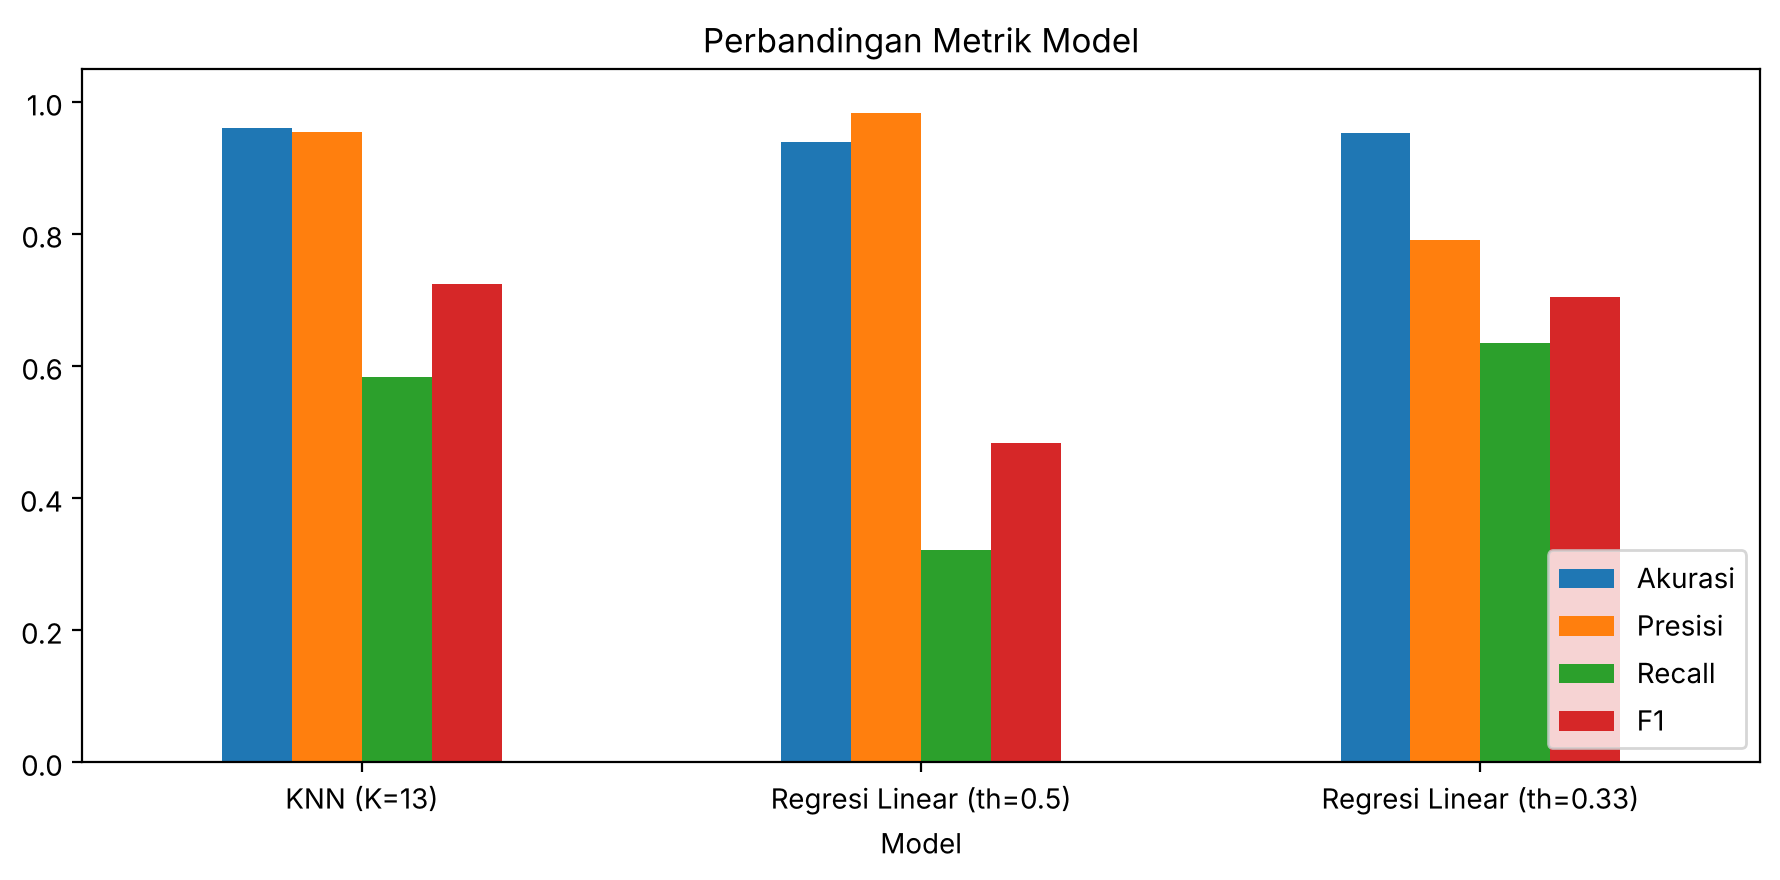

In [19]:
#202431098_Naura Putri
comp = pd.DataFrame({
    "Model": ["KNN (K=%d)" % best_k, "Regresi Linear (th=0.5)", "Regresi Linear (th=%.2f)" % best_th],
    "Akurasi": [acc_knn, res_lr.iloc[0]["Akurasi"], res_lr.iloc[1]["Akurasi"]],
    "Presisi": [pre_knn, res_lr.iloc[0]["Presisi"], res_lr.iloc[1]["Presisi"]],
    "Recall":  [rec_knn, res_lr.iloc[0]["Recall"],  res_lr.iloc[1]["Recall"]],
    "F1":      [f1_knn,  res_lr.iloc[0]["F1"],      res_lr.iloc[1]["F1"]],
}).round(4)
print(comp.to_string(index=False))
print("\nBaseline (selalu menebak 'Tidak Diabetes'):", round(1 - y_test.mean(), 4))

fig, ax = plt.subplots(figsize=(9, 4.5))
comp.set_index("Model")[["Akurasi", "Presisi", "Recall", "F1"]].plot(kind="bar", ax=ax, rot=0)
ax.set_ylim(0, 1.05); ax.set_title("Perbandingan Metrik Model")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()